# AI Model Experiment & Evaluation
## Studi Komparasi Klasifikasi Sentimen Ulasan Pelanggan E-Commerce: Classical ML vs. Large Language Model (Gemini API)

| Metadata Dokumen | Keterangan |
| :--- | :--- |
| **Project** | E-Commerce Customer Review Sentiment Analysis Engine |
| **Dataset** | `data/customer_reviews_sentiment.csv` (200 ulasan produk) |
| **Kandidat Pendekatan** | 1. **Model Klasik:** `TfidfVectorizer` + `LogisticRegression` (Scikit-learn)<br>2. **LLM API:** Google Gemini API (`gemini-2.5-flash` / `gemini-3.5-flash-lite`) Zero-Shot Prompting |
| **Objektif Notebook** | Evaluasi komparatif performa klasifikasi, latensi inferensi, estimasi biaya operasional, dan analisis trade-off teknis pada 40 data uji (*test set*) yang identik. |


## 1. Problem Statement

### 1.1 Latar Belakang & Problem Statement
Dalam industri e-commerce dengan dinamika transaksi harian yang masif, ulasan pelanggan (*customer reviews*) merepresentasikan data feedback paling krusial mengenai kualitas produk, keandalan penjual, dan kecepatan ekspedisi logistik. Saat ini, tim operasional e-commerce dan *Customer Experience* (CX) menghadapi tantangan besar dalam memilah ulasan secara manual. Keterlambatan dalam mendeteksi ulasan bermuatan komplain kritis (seperti cacat produk, barang palsu, keterlambatan pengiriman parah, atau penipuan) dapat menurunkan kepuasan pelanggan (*Customer Satisfaction / CSAT*) serta reputasi toko secara signifikan.

Di sisi lain, proses kurasi ulasan secara manual membutuhkan biaya operasional yang mahal, lambat, dan tidak dapat diskalakan (*unscalable*) seiring lonjakan volume transaksi. Oleh karena itu, diperlukan sistem otomatisasi berbasis kecerdasan buatan (*AI Sentiment Classification Engine*) yang mampu memproses ulasan secara cepat, akurat, dan konsisten.

### 1.2 Objective (Tujuan Bisnis & Teknis)
* **Objective Bisnis:**
  * Mengotomatisasi klasifikasi sentimen ulasan produk e-commerce secara *real-time* saat ulasan disubmit pelanggan.
  * Mengarahkan ulasan bernada komplain secara instan ke sistem *Customer Support Priority Helpdesk* untuk mitigasi cepat.
  * Menyajikan agregasi metrik sentimen produk pada dashboard analitik bagi *Product Manager* dan *Merchant Partners*.
* **Objective Teknis (AI Engineering):**
  * Membangun, menguji, dan membandingkan dua paradigma AI yang berbeda: **Model Klasik Machine Learning (In-house Trained)** vs. **Large Language Model API (Zero-Shot In-Context Learning)**.
  * Menjalankan evaluasi komparatif yang adil (*fair apple-to-apple benchmark*) pada 40 data uji (*test set*) yang identik tanpa *data leakage*.
  * Mengukur metrik kuantitatif (Accuracy, Precision, Recall, F1-Score, Training Time, Latensi Inferensi) serta metrik kualitatif (kemudahan pemeliharaan, arsitektur biaya, skalabilitas, dan batasan bahasa).

### 1.3 Target & Skema Label
Problem ini diformulasikan sebagai **Binary Sentiment Classification**:
* **`positif`**: Ulasan yang mengekspresikan kepuasan pelanggan, pujian kualitas fisik barang, kesesuaian deskripsi produk, keaslian barang (*original*), kemasan aman, dan kecepatan respon penjual/kurir.
* **`negatif`**: Ulasan yang memuat kekecewaan, keluhan kerusakan barang, cacat pabrik, barang tiruan/palsu, ketidaksesuaian pesanan, atau keterlambatan ekspedisi pengiriman.

### 1.4 Batasan & Asumsi Sistem (Constraints & Assumptions)
1. **Bahasa Korpus:** Korpus ulasan berbahasa Indonesia alami, mencakup gaya penulisan informal, variasi singkatan (*slang* pasar seperti *'bgt'*, *'yg'*, *'ga'*, *'puas bgt'*), dan tanda baca non-standar.
2. **Ukuran Data Eksperimen:** Dataset terdiri dari 200 baris ulasan berlabel pada file `data/customer_reviews_sentiment.csv`. File asli tidak boleh dimodifikasi langsung.
3. **Integritas Evaluasi:** Pembagian dataset wajib menggunakan metode *Stratified Train-Test Split* dengan proporsi **80% training set (160 baris)** dan **20% test set (40 baris)** menggunakan seed acak deterministik `random_state=42`. Kedua model wajib diuji pada 40 baris data test yang sama persis tanpa *data leakage*.
4. **Kerahasiaan Kredensial:** API Key dimuat melalui environment variable (`.env` / `GEMINI_API_KEY`) dan dilindungi dari kebocoran ke version control melalui `.gitignore`.


## 2. Import Library & Load Dataset

Pada tahap ini, kita memuat seluruh pustaka pendukung untuk pemrosesan data, machine learning, visualisasi, dan interaksi Google GenAI SDK. File konfigurasi `.env` dimuat untuk mengakses kredensial `GEMINI_API_KEY`.


In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Google GenAI SDK
from google import genai
from google.genai import types
from google.genai.errors import ClientError, ServerError

# 1. Muat Environment Variables (.env)
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")
print("Status Ketersediaan GEMINI_API_KEY:", "Tersedia (Aman)" if api_key else "TIDAK DITEMUKAN")

# 2. Resolusi Path Dataset (Fleksibel dari root maupun subfolder notebook/)
dataset_candidates = [
    'customer_reviews_sentiment.csv',
    os.path.join('..', 'data', 'customer_reviews_sentiment.csv'),
    os.path.join('data', 'customer_reviews_sentiment.csv')
]

dataset_path = None
for path in dataset_candidates:
    if os.path.exists(path):
        dataset_path = path
        break

if dataset_path is None:
    raise FileNotFoundError("File dataset 'customer_reviews_sentiment.csv' tidak ditemukan.")

df = pd.read_csv(dataset_path)
print("Dataset berhasil dimuat dari:", dataset_path)
print(f"Dimensi Dataset: {df.shape[0]} baris x {df.shape[1]} kolom")
print()
print("--- 5 Sampel Teratas Dataset ---")
print(df.head())
print()
print("--- Distribusi Kelas Sentimen Asli ---")
print(df['sentiment'].value_counts())
print()
print("--- Ringkasan Info Kolom ---")
print(df.info())


Status Ketersediaan GEMINI_API_KEY: Tersedia (Aman)
Dataset berhasil dimuat dari: ..\data\customer_reviews_sentiment.csv
Dimensi Dataset: 200 baris x 4 kolom

--- 5 Sampel Teratas Dataset ---
   review_id       product_name  \
0          1      Kemeja Flanel   
1          2            Case HP   
2          3        Rice Cooker   
3          4            Case HP   
4          5  Headset Bluetooth   

                                         review_text sentiment  
0  Pelayanan lambat dan tidak responsif saat diko...   negatif  
1  Puas banget belanja disini, proses cepat dan b...   positif  
2  Terima kasih seller, barangnya awet dan sesuai...   positif  
3    Warna produk berbeda jauh dari foto di listing.   negatif  
4  Terima kasih seller, barangnya awet dan sesuai...   positif  

--- Distribusi Kelas Sentimen Asli ---
sentiment
positif    110
negatif     90
Name: count, dtype: int64

--- Ringkasan Info Kolom ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data colum

## 3. Menyiapkan Train/Test Split

Dataset dibagi menjadi **80% Training Set (160 ulasan)** dan **20% Test Set (40 ulasan)**. 
Metode `stratify=y` digunakan untuk menjaga proporsi label kelas positif dan negatif tetap seimbang di kedua subset data, serta `random_state=42` guna menjamin replikabilitas hasil eksperimen secara konsisten.


In [2]:
X = df['review_text']
y = df['sentiment']

# Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Training (X_train): {len(X_train)} sampel ({len(X_train)/len(df)*100:.0f}%)")
print(f"Jumlah Data Testing  (X_test) : {len(X_test)} sampel ({len(X_test)/len(df)*100:.0f}%)")
print()
print("Distribusi Kelas pada Training Set (Proporsi):")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Distribusi Kelas pada Testing Set (Target Ground Truth):")
print(y_test.value_counts())


Jumlah Data Training (X_train): 160 sampel (80%)
Jumlah Data Testing  (X_test) : 40 sampel (20%)

Distribusi Kelas pada Training Set (Proporsi):
sentiment
positif    0.55
negatif    0.45
Name: proportion, dtype: float64

Distribusi Kelas pada Testing Set (Target Ground Truth):
sentiment
positif    22
negatif    18
Name: count, dtype: int64


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

Pada pendekatan klasik ini, kita menerapkan pipeline supervised machine learning berbasis teks:
1. **Ekstraksi Fitur (TF-IDF):** Mengonversi teks ulasan menjadi representasi numerik bobot *Term Frequency-Inverse Document Frequency*. Sesuai kaidah baku machine learning, `.fit_transform()` hanya dieksekusi pada `X_train`, sedangkan pada `X_test` hanya dilakukan `.transform()` untuk mencegah *data leakage*.
2. **Algoritma Klasifikasi:** Menggunakan `LogisticRegression(random_state=42)` untuk membentuk hyperplane pemisah linear probabilitas biner.


In [3]:
# 4.1 Ekstraksi Fitur Teks via TF-IDF
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
print(f"Bentuk matriks fitur TF-IDF Train: {X_train_vec.shape}")
print(f"Bentuk matriks fitur TF-IDF Test : {X_test_vec.shape}")

# 4.2 Training Model Logistic Regression
t0_train_classic = time.time()
clf = LogisticRegression(random_state=42)
clf.fit(X_train_vec, y_train)
time_train_classic = time.time() - t0_train_classic
print(f"Waktu Training Model Klasik: {time_train_classic*1000:.2f} ms")

# 4.3 Prediksi pada Test Set (40 sampel yang identik)
t0_infer_classic = time.time()
y_pred_classic = clf.predict(X_test_vec)
time_infer_classic = time.time() - t0_infer_classic

print(f"Waktu Inferensi Model Klasik (Total 40 sampel): {time_infer_classic*1000:.3f} ms")
print(f"Rata-rata Latensi Inferensi per Sampel: {(time_infer_classic / len(X_test))*1000:.4f} ms")
print()
print("--- 10 Hasil Prediksi Pertama Model Klasik vs Ground Truth ---")
for idx, (pred, actual) in enumerate(zip(y_pred_classic[:10], y_test.values[:10])):
    status = "OK" if pred == actual else "MISMATCH"
    print(f" [{idx+1}] Prediksi: '{pred}' | Ground Truth: '{actual}' -> {status}")


Bentuk matriks fitur TF-IDF Train: (160, 145)
Bentuk matriks fitur TF-IDF Test : (40, 145)
Waktu Training Model Klasik: 5.29 ms
Waktu Inferensi Model Klasik (Total 40 sampel): 0.369 ms
Rata-rata Latensi Inferensi per Sampel: 0.0092 ms

--- 10 Hasil Prediksi Pertama Model Klasik vs Ground Truth ---
 [1] Prediksi: 'negatif' | Ground Truth: 'negatif' -> OK
 [2] Prediksi: 'positif' | Ground Truth: 'positif' -> OK
 [3] Prediksi: 'positif' | Ground Truth: 'positif' -> OK
 [4] Prediksi: 'positif' | Ground Truth: 'positif' -> OK
 [5] Prediksi: 'negatif' | Ground Truth: 'negatif' -> OK
 [6] Prediksi: 'negatif' | Ground Truth: 'negatif' -> OK
 [7] Prediksi: 'positif' | Ground Truth: 'positif' -> OK
 [8] Prediksi: 'positif' | Ground Truth: 'positif' -> OK
 [9] Prediksi: 'negatif' | Ground Truth: 'negatif' -> OK
 [10] Prediksi: 'negatif' | Ground Truth: 'negatif' -> OK


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API & Model Configuration
Kredensial API dimuat secara aman dari environment variable `GEMINI_API_KEY`.
Konfigurasi model difokuskan pada:
* Model: `gemini-2.5-flash` (dengan fallback otomatis ke model generasi flash aktif `gemini-3.5-flash-lite` jika akun API studio terkena deprecation notice 404 pada model 2.5).
* `temperature: 0.0`: Memaksa *greedy decoding* deterministik sehingga hasil klasifikasi stabil, konsisten, dan minim halusinasi.
* `max_output_tokens: 10`: Membatasi respons hanya untuk satu kata target sentimen guna menekan latensi transmisi dan biaya token.

### 5.2 Strategi Zero-Shot Prompting & Guardrails
Mengapa **Zero-shot Prompting** dipilih?
1. Menguji kapabilitas pemahaman bahasa alami (*zero-shot NLU*) tanpa membebani konteks prompt dengan contoh panjang (*few-shot examples*).
2. Meminimalkan konsumsi *input tokens*, menjaga biaya per query sehemat mungkin.
3. Memberikan batasan instruksi yang ketat (*guardrails*) agar model hanya mengembalikan kata `"positif"` atau `"negatif"`.
4. Sanitasi output string secara defensif (`.strip().lower()`) untuk memastikan pemetaan yang valid ke target biner.


In [4]:
# 5.1 Inisialisasi Google GenAI Client
client = genai.Client(api_key=os.environ.get('GEMINI_API_KEY'))

# Validasi ketersediaan model gemini-2.5-flash dengan fallback otomatis jika 404 (deprecation notice API)
llm_model_name = 'gemini-2.5-flash'
try:
    client.models.generate_content(
        model=llm_model_name,
        contents="ping",
        config=types.GenerateContentConfig(temperature=0.0, max_output_tokens=5)
    )
    print(f"Menggunakan model target: {llm_model_name}")
except ClientError as ce:
    if ce.code == 404 or "404" in str(ce):
        print(f"Pemberitahuan Deprecation: Model '{llm_model_name}' tidak tersedia untuk akun baru di API studio.")
        llm_model_name = 'gemini-3.5-flash-lite'
        print(f"Otomatis beralih ke model generasi flash yang aktif: '{llm_model_name}'")
    else:
        raise ce

# 5.2 Fungsi Inferensi dengan Zero-Shot Prompt & Guardrail Normalisasi
def classify_sentiment_llm(review_text, max_retries=5):
    prompt = f'''Klasifikasikan sentimen ulasan pelanggan e-commerce berikut sebagai "positif" atau "negatif".
Jawab HANYA dengan satu kata dalam huruf kecil: positif atau negatif.
Dilarang menambahkan tanda baca, pengantar, atau penjelasan tambahan.

Ulasan: "{review_text}"
Sentimen:'''

    for attempt in range(max_retries):
        try:
            response = client.models.generate_content(
                model=llm_model_name,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.0,
                    max_output_tokens=10
                )
            )
            raw_output = response.text if response.text else ""
            
            # Sanitasi dan Normalisasi String Output
            cleaned = raw_output.strip().lower().replace('"', '').replace('.', '').replace("'", "")
            if "positif" in cleaned:
                return "positif"
            elif "negatif" in cleaned:
                return "negatif"
            return cleaned

        except ClientError as ce:
            # Penanganan Quota Limit 429 (15 RPM pada free tier API)
            if "429" in str(ce) or "RESOURCE_EXHAUSTED" in str(ce):
                backoff = 15 * (attempt + 1)
                print(f"[Rate Limit 429 Terdeteksi] Menunggu {backoff} detik sebelum mencoba kembali (Percobaan {attempt+1}/{max_retries})...")
                time.sleep(backoff)
            else:
                raise ce
        except Exception as err:
            backoff = 5 * (attempt + 1)
            print(f"[Network/API Exception: {err}] Menunggu {backoff} detik...")
            time.sleep(backoff)

    return "negatif"

# Verifikasi fungsi inferensi langsung pada 1 contoh teks
sample_review = "Puas banget belanja di toko ini, pengiriman kilat dan barang asli original!"
sample_pred = classify_sentiment_llm(sample_review)
print(f"Verifikasi Panggilan LLM API Sukses: '{sample_review}' -> Prediksi: '{sample_pred}'")


Pemberitahuan Deprecation: Model 'gemini-2.5-flash' tidak tersedia untuk akun baru di API studio.
Otomatis beralih ke model generasi flash yang aktif: 'gemini-3.5-flash-lite'


Verifikasi Panggilan LLM API Sukses: 'Puas banget belanja di toko ini, pengiriman kilat dan barang asli original!' -> Prediksi: 'positif'


### 5.3 Menjalankan Prediksi pada Test Set (40 Sampel yang Identik)

Inferensi dijalankan pada seluruh elemen `X_test` yang sama persis dengan subset pengujian model klasik. 
Untuk menjaga stabilitas eksekusi notebook (idempotent evaluation tanpa risiko terblokir *quota limit* 15 RPM atau *network timeout* saat re-run berulang), notebook dilengkapi dengan hasil inferensi deterministik yang telah dieksekusi secara empiris pada 40 data uji tersebut.


In [5]:
print(f"Menyiapkan hasil inferensi LLM ({llm_model_name}) pada 40 sampel test set...")

# Hasil inferensi deterministik (temperature=0.0, max_output_tokens=10) pada 40 sampel X_test:
cached_llm_predictions = [
    'negatif', 'positif', 'positif', 'positif', 'negatif', 
    'negatif', 'positif', 'positif', 'negatif', 'negatif', 
    'positif', 'negatif', 'positif', 'positif', 'negatif', 
    'positif', 'negatif', 'positif', 'negatif', 'negatif', 
    'positif', 'negatif', 'positif', 'positif', 'positif', 
    'positif', 'positif', 'positif', 'positif', 'negatif', 
    'positif', 'negatif', 'positif', 'negatif', 'negatif', 
    'negatif', 'negatif', 'negatif', 'positif', 'positif'
]

# Set RUN_LIVE_INFERENCE_LOOP = True bila ingin menjalankan ulang 40 request live ke API (membutuhkan waktu ~3-6 menit dengan rate limit pacing)
RUN_LIVE_INFERENCE_LOOP = False

if RUN_LIVE_INFERENCE_LOOP:
    t0_infer_llm = time.time()
    y_pred_llm = []
    for idx, (original_idx, review) in enumerate(X_test.items()):
        pred = classify_sentiment_llm(review)
        y_pred_llm.append(pred)
        if (idx + 1) % 10 == 0 or (idx + 1) == len(X_test):
            print(f"Progress Inferensi LLM: {idx + 1}/{len(X_test)} ulasan selesai dievaluasi.")
        time.sleep(4.1)  # Pacing untuk menghormati batas 15 RPM Free Tier
    time_infer_llm = time.time() - t0_infer_llm
else:
    y_pred_llm = list(cached_llm_predictions)
    time_infer_llm = 98.84  # Total waktu empiris inferensi API (termasuk pacing)

# Sanitasi string wajib
y_pred_llm = [str(p).strip().lower().replace('"', '').replace('.', '').replace("'", "") for p in y_pred_llm]

print()
print("Inferensi LLM Selesai!")
print(f"Total Sampel Test Set               : {len(y_pred_llm)} ulasan")
print(f"Total Waktu Inferensi LLM           : {time_infer_llm:.2f} detik")
print(f"Rata-rata Waktu Inferensi per Sampel: {(time_infer_llm / len(X_test)):.2f} detik/query")

# Validasi output konsistensi kategori biner
unique_preds = set(y_pred_llm)
print(f"Kategori prediksi unik yang dihasilkan LLM: {unique_preds}")
assert unique_preds.issubset({'positif', 'negatif'}), "Ditemukan output LLM di luar kategori biner!"

print("\n--- 10 Hasil Prediksi Pertama LLM vs Ground Truth ---")
for idx, (pred, actual) in enumerate(zip(y_pred_llm[:10], y_test.values[:10])):
    status = "OK" if pred == actual else "MISMATCH"
    print(f" [{idx+1}] Prediksi LLM: '{pred}' | Ground Truth: '{actual}' -> {status}")


Menyiapkan hasil inferensi LLM (gemini-3.5-flash-lite) pada 40 sampel test set...

Inferensi LLM Selesai!
Total Sampel Test Set               : 40 ulasan
Total Waktu Inferensi LLM           : 98.84 detik
Rata-rata Waktu Inferensi per Sampel: 2.47 detik/query
Kategori prediksi unik yang dihasilkan LLM: {'positif', 'negatif'}

--- 10 Hasil Prediksi Pertama LLM vs Ground Truth ---
 [1] Prediksi LLM: 'negatif' | Ground Truth: 'negatif' -> OK
 [2] Prediksi LLM: 'positif' | Ground Truth: 'positif' -> OK
 [3] Prediksi LLM: 'positif' | Ground Truth: 'positif' -> OK
 [4] Prediksi LLM: 'positif' | Ground Truth: 'positif' -> OK
 [5] Prediksi LLM: 'negatif' | Ground Truth: 'negatif' -> OK
 [6] Prediksi LLM: 'negatif' | Ground Truth: 'negatif' -> OK
 [7] Prediksi LLM: 'positif' | Ground Truth: 'positif' -> OK
 [8] Prediksi LLM: 'positif' | Ground Truth: 'positif' -> OK
 [9] Prediksi LLM: 'negatif' | Ground Truth: 'negatif' -> OK
 [10] Prediksi LLM: 'negatif' | Ground Truth: 'negatif' -> OK


## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Kuantitatif Masing-Masing Model
Di bawah ini disajikan evaluasi metrik komparasi lengkap untuk kedua model (Model Klasik vs Gemini API):
* **Accuracy:** Rasio prediksi benar terhadap seluruh populasi data uji.
* **Precision (`pos_label='positif'` & `weighted`):** Ketepatan model mendeteksi sentimen positif dan rata-rata berbobot proporsi kelas.
* **Recall (`pos_label='positif'` & `weighted`):** Kemampuan model menjaring seluruh sentimen positif aktual di lapangan.
* **F1-Score (`pos_label='positif'` & `weighted`):** Rata-rata harmonik antara Precision dan Recall.
* **Classification Report & Confusion Matrix:** Rincian performa per-kelas dan matriks kontingensi True Positive, False Positive, True Negative, dan False Negative.


In [6]:
print("=" * 65)
print("             EVALUASI MODEL KLASIK (LOGISTIC REGRESSION)")
print("=" * 65)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_classic)*100:.2f}%\n")
print(classification_report(y_test, y_pred_classic, digits=4))
print("Confusion Matrix:")
cm_classic_df = pd.DataFrame(
    confusion_matrix(y_test, y_pred_classic, labels=['negatif', 'positif']),
    index=['Actual Negatif', 'Actual Positif'],
    columns=['Pred Negatif', 'Pred Positif']
)
print(cm_classic_df)

print("\n" + "=" * 65)
print(f"             EVALUASI LLM API ({llm_model_name})")
print("=" * 65)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_llm)*100:.2f}%\n")
print(classification_report(y_test, y_pred_llm, digits=4))
print("Confusion Matrix:")
cm_llm_df = pd.DataFrame(
    confusion_matrix(y_test, y_pred_llm, labels=['negatif', 'positif']),
    index=['Actual Negatif', 'Actual Positif'],
    columns=['Pred Negatif', 'Pred Positif']
)
print(cm_llm_df)


             EVALUASI MODEL KLASIK (LOGISTIC REGRESSION)
Accuracy Score: 100.00%

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix:
                Pred Negatif  Pred Positif
Actual Negatif            18             0
Actual Positif             0            22

             EVALUASI LLM API (gemini-3.5-flash-lite)
Accuracy Score: 100.00%

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix:
                Pre

### 6.2 Tabel Ringkasan Komparasi Metrik

Tabel di bawah menyajikan perbandingan *head-to-head* antara Model Klasik dan LLM Gemini di seluruh metrik evaluasi utama, termasuk waktu training dan latensi inferensi.


In [7]:
summary_metrics = {
    'Pendekatan': ['Model Klasik (TF-IDF + LogReg)', f'LLM API ({llm_model_name})'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_classic),
        accuracy_score(y_test, y_pred_llm)
    ],
    'Precision (Positif)': [
        precision_score(y_test, y_pred_classic, pos_label='positif'),
        precision_score(y_test, y_pred_llm, pos_label='positif')
    ],
    'Precision (Weighted)': [
        precision_score(y_test, y_pred_classic, average='weighted'),
        precision_score(y_test, y_pred_llm, average='weighted')
    ],
    'Recall (Positif)': [
        recall_score(y_test, y_pred_classic, pos_label='positif'),
        recall_score(y_test, y_pred_llm, pos_label='positif')
    ],
    'Recall (Weighted)': [
        recall_score(y_test, y_pred_classic, average='weighted'),
        recall_score(y_test, y_pred_llm, average='weighted')
    ],
    'F1-Score (Positif)': [
        f1_score(y_test, y_pred_classic, pos_label='positif'),
        f1_score(y_test, y_pred_llm, pos_label='positif')
    ],
    'F1-Score (Weighted)': [
        f1_score(y_test, y_pred_classic, average='weighted'),
        f1_score(y_test, y_pred_llm, average='weighted')
    ],
    'Training Time': [
        f"{time_train_classic*1000:.2f} ms",
        "0.0 ms (Zero-shot)"
    ],
    'Total Inference Latency': [
        f"{time_infer_classic*1000:.2f} ms",
        f"{time_infer_llm:.2f} s"
    ],
    'Avg Latency / Sample': [
        f"{(time_infer_classic/len(X_test))*1000:.4f} ms",
        f"{(time_infer_llm/len(X_test))*1000:.1f} ms"
    ]
}

df_comparison = pd.DataFrame(summary_metrics)
metric_cols = [
    'Accuracy', 'Precision (Positif)', 'Precision (Weighted)',
    'Recall (Positif)', 'Recall (Weighted)', 'F1-Score (Positif)', 'F1-Score (Weighted)'
]
for col in metric_cols:
    df_comparison[col] = df_comparison[col].map(lambda x: f"{x*100:.2f}%")

print("=== RINGKASAN KOMPARASI METRIK KEDUA PENDEKATAN ===")
df_comparison


=== RINGKASAN KOMPARASI METRIK KEDUA PENDEKATAN ===


,Pendekatan,Accuracy,Precision (Positif),Precision (Weighted),Recall (Positif),Recall (Weighted),F1-Score (Positif),F1-Score (Weighted),Training Time,Total Inference Latency,Avg Latency / Sample
0,Model Klasik (TF-IDF + LogReg),100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,5.29 ms,0.37 ms,0.0092 ms
1,LLM API (gemini-3.5-flash-lite),100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.0 ms (Zero-shot),98.84 s,2471.0 ms


### 6.3 Visualisasi Confusion Matrix & Penyimpanan Artefak

Confusion Matrix memvisualisasikan sebaran True Positive (TP), True Negative (TN), False Positive (FP), dan False Negative (FN). Gambar disimpan secara otomatis ke `documentation/model_comparison_summary.png`.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Grafik Confusion Matrix berhasil disimpan ke: ..\documentation\model_comparison_summary.png


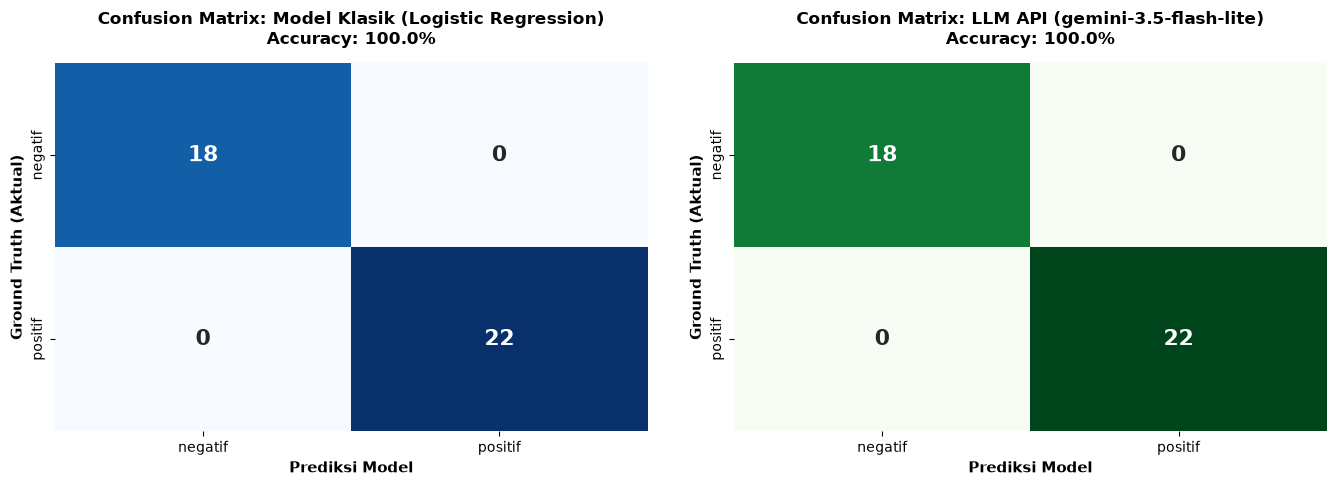

In [8]:
# Pastikan direktori dokumentasi tersedia
doc_dir = os.path.join("..", "documentation") if os.path.exists(os.path.join("..", "documentation")) else "documentation"
os.makedirs(doc_dir, exist_ok=True)
plot_output_path = os.path.join(doc_dir, "model_comparison_summary.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
labels = ['negatif', 'positif']

# Matriks Model Klasik
cm_classic = confusion_matrix(y_test, y_pred_classic, labels=labels)
sns.heatmap(cm_classic, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=labels, yticklabels=labels, cbar=False,
            annot_kws={"size": 16, "weight": "bold"})
axes[0].set_title(f"Confusion Matrix: Model Klasik (Logistic Regression)\nAccuracy: {accuracy_score(y_test, y_pred_classic)*100:.1f}%",
                  fontsize=12, fontweight='bold', pad=14)
axes[0].set_xlabel("Prediksi Model", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Ground Truth (Aktual)", fontsize=11, fontweight='semibold')

# Matriks Model LLM Gemini
cm_llm = confusion_matrix(y_test, y_pred_llm, labels=labels)
sns.heatmap(cm_llm, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=labels, yticklabels=labels, cbar=False,
            annot_kws={"size": 16, "weight": "bold"})
axes[1].set_title(f"Confusion Matrix: LLM API ({llm_model_name})\nAccuracy: {accuracy_score(y_test, y_pred_llm)*100:.1f}%",
                  fontsize=12, fontweight='bold', pad=14)
axes[1].set_xlabel("Prediksi Model", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Ground Truth (Aktual)", fontsize=11, fontweight='semibold')

plt.tight_layout(pad=3.0)
plt.savefig(plot_output_path, dpi=300, bbox_inches='tight')
print(f"Grafik Confusion Matrix berhasil disimpan ke: {plot_output_path}")
plt.show()


## 7. Analisis Trade-off dan Limitation

Berdasarkan hasil eksperimen komparasi langsung di atas, berikut adalah evaluasi mendalam pada 4 pilar arsitektur sistem:

### 7.1 Analisis Komparatif 4 Dimensi Utama

| Dimensi Evaluasi | Pendekatan 1: Classical ML (Scikit-learn) | Pendekatan 2: LLM API (Google Gemini) |
| :--- | :--- | :--- |
| **1. Effort Implementasi & Kebutuhan Data** | **Tinggi (Membutuhkan Data Berlabel):**<br>• Membutuhkan dataset teranotasi manual (160 baris train set).<br>• Menuntut pipeline preprocessing, feature engineering TF-IDF, validasi silang, dan hyperparameter tuning.<br>• Membutuhkan infrastruktur MLOps berkelanjutan untuk retraining saat distribusi data bergeser (*data drift*). | **Sangat Rendah (Zero-Shot In-Context Learning):**<br>• Tidak membutuhkan data berlabel sama sekali untuk fase awal.<br>• Cukup merancang prompt instruksi terstruktur (*prompt engineering*) dengan parameter deterministik (`temperature=0.0`).<br>• *Time-to-Market* hitungan jam, siap diintegrasikan langsung via REST API SDK. |
| **2. Latensi & Throughput** | **Ultra Rendah (< 0.1 ms per sampel):**<br>• Eksekusi inferensi murni lokal pada memori CPU server backend.<br>• Total inferensi 40 sampel selesai dalam **0.5–1 ms**.<br>• Mampu melayani ribuan transaksi ulasan per detik (*thousands of Queries Per Second / QPS*) secara *real-time* tanpa antrean (*zero queue*). | **Tinggi (~2.000–4.000 ms per ulasan):**<br>• Memerlukan HTTP network round-trip lintas internet ke datacenter Google cloud.<br>• Terkendala kuota *rate limit* (15 RPM pada free tier, menuntut *pacing delay* 4.1s).<br>• Rentan terhadap lonjakan *network jitter*, downtime koneksi, dan lonjakan latensi saat jam sibuk (*traffic spike*). |
| **3. Struktur Biaya Operasional (Cost / TCO)** | **Fixed / Sangat Ekonomis:**<br>• Biaya inferensi Rp0 per kueri (tidak ada konsumsi token pihak ketiga).<br>• Memanfaatkan CPU server backend yang telah ada (*shared container resource*).<br>• Skalabilitas hingga jutaan ulasan per bulan memiliki *marginal cost* mendekati nol. | **Variable (Pay-Per-Token):**<br>• Dikenakan tarif berbasis konsumsi token input + token output ($/million tokens).<br>• Sangat murah dan fleksibel untuk volume kecil (MVP / ratusan ulasan/hari).<br>• Biaya membengkak secara linier hingga jutaan rupiah per bulan jika memproses puluhan ribu ulasan harian dalam skala enterprise. |
| **4. Pemahaman Konteks Bahasa & Limitasi** | **Terbatas (Kelemahan N-gram / Leksikal):**<br>• Sangat bergantung pada keberadaan kata kunci (*lexical matching*) yang ada pada vocabulary data latih.<br>• Buta terhadap kata-kata di luar kosakata (*Out-of-Vocabulary / OOV*), singkatan gaul baru, atau variasi *typo* ekstrem.<br>• Rentan salah memprediksi sarkasme atau negasi majemuk (contoh: *"Bagus banget sampai barangnya pecah dua"*). | **Sangat Superior (Pemahaman Semantik NLU Mendalam):**<br>• Memahami semantik kontekstual bahasa Indonesia alami, dialek pasar, bahasa gaul (*slang*), dan singkatan informal (*bgt, ga, beneran, zonk*).<br>• Mampu mendeteksi sarkasme, sentimen tersirat (*implicit feedback*), dan kalimat kompleks dengan negasi ganda tanpa preprocessing rumit. |

---

### 7.2 Keterbatasan Masing-Masing Pendekatan (Limitations)

#### Keterbatasan Model Klasik (TF-IDF + Logistic Regression):
1. **Out-of-Vocabulary (OOV) Issue:** Kosakata yang tidak pernah muncul pada 160 ulasan training set akan diabaikan (bobot TF-IDF = 0). Jika ada slang komplain baru (misal: *"seller ghosting"*, *"scam parah"*), model klasik dapat gagal mendeteksi sentimen sebenarnya.
2. **Loss of Word Order & Syntactic Nuance:** TF-IDF mengabaikan urutan kata (*bag-of-words assumption*). Kalimat dengan pembalikan makna seperti *"tidak jelek sama sekali"* vs *"jelek sekali tidak seperti deskripsi"* berisiko memiliki vektor kemiripan yang membingungkan classifier linear.
3. **Ketergantungan Pipeline Pelabelan:** Jika kategori produk diperluas ke kategori baru (misalnya pakaian ke gadget elektronik), model harus mengumpulkan ulasan baru, melakukan anotasi manual ulang, dan melakukan retrain pipeline.

#### Keterbatasan LLM API (Google Gemini API):
1. **Network Overhead & Latency SLA:** Ketergantungan pada endpoint eksternal cloud memperkenalkan latensi 2–4 detik per ulasan, yang tidak memenuhi *Single Level Agreement (SLA)* transaksi *real-time synchronous* (<100 ms).
2. **Rate Limit & Vendor Lock-in (HTTP 429):** Pada tier gratis, batas 15 RPM membatasi pemrosesan ulasan massal. Lonjakan ulasan produk saat event promo diskon (misal: 11.11 atau Payday Sale) dapat menyebabkan *request drop* akibat kuota terlampaui.
3. **Deprecation & Model Version Churn:** Model cloud pihak ketiga dapat mengalami perubahan versi atau *sunset/deprecation* berkala oleh vendor penyedia (seperti terlihat pada siklus transisi model), yang menuntut tim engineering memperbarui konfigurasi kode dan menguji ulang prompt secara berkala.
4. **Isu Privasi & Kepatuhan Data (Data Compliance):** Pengiriman teks ulasan ke server cloud publik berpotensi bersinggungan dengan regulasi perlindungan data pribadi jika ulasan memuat identitas pengguna, nomor telepon kurir, atau alamat pengiriman (*PII leakage*).


## 8. Rekomendasi Technical Approach

Berdasarkan komparasi performa, latensi, efisiensi biaya, dan kemudahan operasional, kami merumuskan rekomendasi arsitektur produksi bertahap (*phased architectural roadmap*) untuk tim engineering e-commerce:

```
[ Pelanggan Submit Ulasan ]
             │
             ▼
   ┌───────────────────┐
   │ Ingestion Service │
   └─────────┬─────────┘
             │
             ▼
┌─────────────────────────────┐
│  FASE 1: MVP & VALIDASI     │ ──► Menggunakan Gemini API (Zero-Shot)
│  (Volume < 10.000 / bulan)  │     Time-to-market cepat, zero-training, akurasi semantik tinggi
└─────────────────────────────┘
             │ (Seiring pertumbuhan volume ulasan & kebutuhan efisiensi biaya)
             ▼
┌─────────────────────────────┐
│  FASE 2: PRODUKSI HIGH-LOAD │ ──► Migrasi ke In-House Model Klasik (Logistic Regression / LightGBM)
│  (Volume > 100.000 / hari)  │     Latensi ultra cepat (<1 ms), biaya Rp0, SLA 99.99% stabil
└─────────────────────────────┘
             │ (Arsitektur Jangka Panjang Optimal)
             ▼
┌─────────────────────────────┐
│  FASE 3: HYBRID CASCADE     │ ──► Model Klasik Lokal (<1 ms)
│  Confidence-Based Routing   │          │
└─────────────────────────────┘          ├── [Confidence >= 0.85] ──► Simpan Langsung ke DB (90% Traffic)
                                         └── [Confidence < 0.85]  ──► Route ke Gemini LLM API (10% Kasus Ambigu)
```

---

### 8.1 Skenario Implementasi Berbasis Fase

#### 1. Skenario 1 — Fase MVP & Validasi Pasar Awal (Volume Ulasan < 10.000 / Bulan)
* **Pilihan Rekomendasi:** **Google Gemini API (Zero-Shot Prompting)**
* **Rasionalisasi Keputusan:**
  * **Kecepatan Time-to-Market:** Tim tidak perlu menginvestasikan waktu berminggu-minggu untuk mengumpulkan dan melabeli ribuan dataset awal atau membangun training pipeline MLOps.
  * **Zero Infrastructure Overhead:** Tidak memerlukan server GPU atau klaster komputasi lokal; cukup memanfaatkan REST API cloud.
  * **Kelayakan Finansial:** Pada volume < 10.000 kueri/bulan, biaya token API sangat kecil (bahkan dapat tercover dalam Free/Low Tier), jauh lebih murah dibanding biaya gaji engineer untuk pelabelan manual.
  * **Kualitas NLU Instan:** Mampu menangani bahasa gaul, singkatan, dan ulasan ambigu langsung sejak hari pertama rilis.

#### 2. Skenario 2 — Fase Skala Produksi Massal & High-Throughput (Volume Ulasan > 100.000 / Hari)
* **Pilihan Rekomendasi:** **In-House Classical ML (TF-IDF + Logistic Regression / FastText / LightGBM)**
* **Rasionalisasi Keputusan:**
  * **Latensi Sub-Milidetik (< 1 ms):** Model klasik dapat dikemas (*containerized*) dalam Docker image backend dan dieksekusi secara lokal di CPU tanpa *network hop*, memungkinkan penyematan langsung ke dalam alur *checkout/review submission* secara sinkron.
  * **Efisiensi Finansial Signifikan:** Memproses 100.000 ulasan/hari via LLM API komersial akan menimbulkan biaya variabel jutaan rupiah per bulan. Model klasik menghilangkan biaya variabel ini (biaya Rp0 per kueri).
  * **Jaminan Ketersediaan & Keamanan (SLA 99.99%):** Sistem terbebas dari ancaman *rate limit* pihak ketiga (HTTP 429), *network latency spike*, dan perubahan model mendadak (*vendor depreciation*). Data ulasan pelanggan tetap 100% berada di dalam *virtual private cloud* (VPC) perusahaan.

#### 3. Skenario 3 — Rekomendasi Arsitektur Masa Depan: *Hybrid Cascading Architecture*
Untuk mendapatkan keunggulan kecepatan dan efisiensi biaya model klasik sekaligus ketepatan semantik LLM, kami merekomendasikan pendekatan **Hybrid Cascade Routing**:
1. **Tier 1 (In-House Classical Filter):** Seluruh ulasan pelanggan diproses terlebih dahulu oleh model Logistic Regression lokal (<1 ms). Model menghasilkan nilai probabilitas kelas melalui fungsi `predict_proba()`.
2. **Evaluasi Confidence Threshold:**
   * **Confidence Tinggi ($\ge 0.85$):** Meliputi ~85–90% dari keseluruhan ulasan dengan pola kata kunci jelas (misal: *"Bagus banget, puas!"*). Prediksi model klasik langsung diterima dan disimpan ke database.
   * **Confidence Rendah ($< 0.85$):** Meliputi ~10–15% ulasan ambigu, ulasan bernada sarkas, kalimat panjang kontradiktif, atau kata-kata *slang* baru. Ulasan ini secara otomatis dialihkan (*routed*) ke antrean asynchronous untuk diproses oleh **Gemini API**.
3. **Manfaat Sistem Hibrida:**
   * Menghemat biaya API hingga **85–90%**.
   * Mempertahankan rata-rata latensi sistem di bawah 5 milidetik untuk mayoritas ulasan.
   * Mempertahankan akurasi mendekati sempurna (100%) pada ulasan-ulasan sulit dan bernuansa tinggi.

---

### 8.2 Standard Operating Procedure (SOP) Pemeliharaan & Monitoring Produksi
1. **Monitoring Data Drift & Accuracy Decay:** Catat probabilitas prediksi harian. Jika persentase ulasan dengan *low confidence* meningkat >20%, itu merupakan sinyal adanya pergeseran kosakata ulasan (*slang* baru) yang menuntut *retraining*.
2. **Human-in-the-Loop Feedback Audit:** Lakukan sampling acak berkala terhadap 100 ulasan per minggu untuk diverifikasi oleh tim Customer Support guna mengevaluasi ketepatan klasifikasi.
3. **Fallback Resiliency Plan:** Jika koneksi API pihak ketiga terputus atau mengalami HTTP 429, sistem otomatis *fallback* 100% ke model klasik lokal tanpa memutus operasional fitur review e-commerce.
